<a href="https://colab.research.google.com/github/ContiPaolo/EKF-SINDy/blob/main/notebooks/CoupledOscillators_StifnessEstimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
###########################  INSTALL EKF-SINDY (Colab only)  ###########################
# On Colab this installs the package and its dependencies (pysindy, jax, ...).
# Locally: run `uv sync` in the repository and select the `.venv` kernel.
import sys

if "google.colab" in sys.modules:
    %pip install -q "ekfsindy @ git+https://github.com/ContiPaolo/EKF-SINDy"

In [2]:
%matplotlib inline


###########################                LIBRARIES                ###########################
import matplotlib.pyplot as plt
import numpy as np
import pysindy as ps
from scipy.integrate import odeint
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

from ekfsindy import AugmentedEKF, SparseModel, SymbolicLibrary, observation, systems
from ekfsindy.data import TimeDelayEmbedding, add_noise_with_snr
from ekfsindy.plotting import plot_estimate, plot_estimates

seed = 1

## Coupled Oscillators:
### Estimation of the stifness $k_2$ of the hidden oscillator.

We consider two coupled oscillators with the following equations of motion:

$$
\begin{align}
& m_1\ddot{u}_1 + c_1 \dot{u}_1 + k_1 u_1 + \alpha u_2 = 0, \\
& m_2\ddot{u}_2 + c_2 \dot{u}_2 + k_2 u_2 + \alpha u_1 + \beta u_1^2 + \gamma u_2^3 = 0,
\end{align}
$$

which can be rewritten at first order as:

$$
\begin{align}
\dot{u}_1 &= v_1, \\
m_1\dot{v}_1 &= -c_1 v_1 - k_1 u_1 - \alpha u_2, \\
\dot{u}_2 &= v_2, \\
m_2\dot{v}_2 &= - c_2 v_2 - k_2 u_2 - \alpha u_1 - \beta u_1^2 - \gamma u_2^3.
\end{align}
$$

We suppose we are only able to measure the position of the first oscillator $u_1$, and we aim to:

1. **Identify the equations of motion from the data (SINDy).**
2. **Estimate the states and the stifness $k_2$ of the hidden oscillator.**

In [3]:
######################       PROBLEM SETUP       ######################
# Equations of motion in `ekfsindy.systems.coupled_oscillators`
system = {
    # Natural frequency of the oscillators:
    "k1": (1.0)**2,
    # Coupling:
    "beta": 2e-3,  # quadratic
    "alpha": -1e-1,  # linear
    # k2: to be estimated
    # Damping:
    "c1": 2e-2,
    "c2": 1.95e-2,
    # Cubic nonlinearity:
    "gamma": 1e-3,
    # Time span and time step:
    "t0": 0.0,
    "T_end": 200.0,
    "dt": 1e-2,
}

t0, T_end, dt = system["t0"], system["T_end"], system["dt"]
t = np.arange(t0, T_end, dt)
T = len(t)

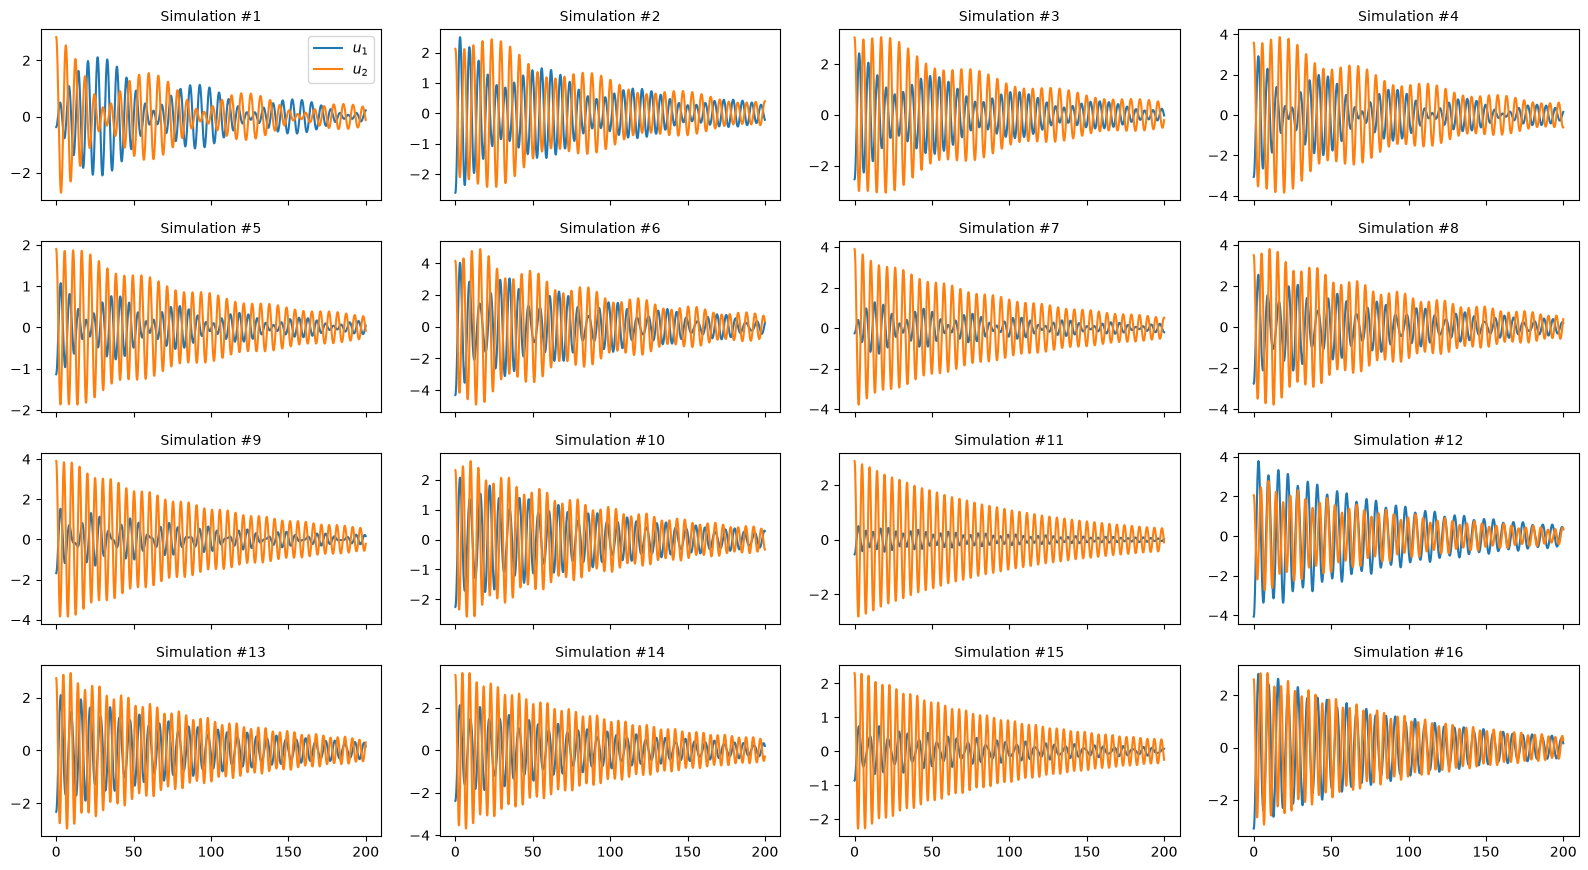

In [4]:
######################       GENERATE DATA       ######################
#Number of instances
n_ics = 16

#Random initial displacements, zero initial velocities:
np.random.seed(seed=seed)
u1_0 = np.random.normal(-2, 1, n_ics)
u2_0 = np.random.normal(3, 1, n_ics)

#Equispaced values of k2 in the range P_k = [1., 2.]
param_names = ["k2"]
params = np.linspace(1.0, 2.0, n_ics)[:, None]

X = []
for num_sim in range(n_ics):
    system.update(dict(zip(param_names, params[num_sim])))
    y0 = [u1_0[num_sim], 0.0, u2_0[num_sim], 0.0]
    X.append(odeint(systems.coupled_oscillators, y0, t, args=(system,)))
X = np.array(X)

fig, axes = plt.subplots(int(np.ceil(n_ics / 4)), 4, figsize=(16, 2.2 * np.ceil(n_ics / 4)), sharex=True)
for num_sim, ax in enumerate(axes.flat):
    ax.plot(t, X[num_sim, :, 0], label="$u_1$")
    ax.plot(t, X[num_sim, :, 2], label="$u_2$")
    ax.set_title(f"Simulation #{num_sim + 1}", fontsize=10)
axes.flat[0].legend()
fig.tight_layout()
plt.show()

#Split the data into training and test sets:
X_train, X_test, param_train, param_test = train_test_split(X, params, test_size=0.2, random_state=seed)
n_train, n_test = len(X_train), len(X_test)

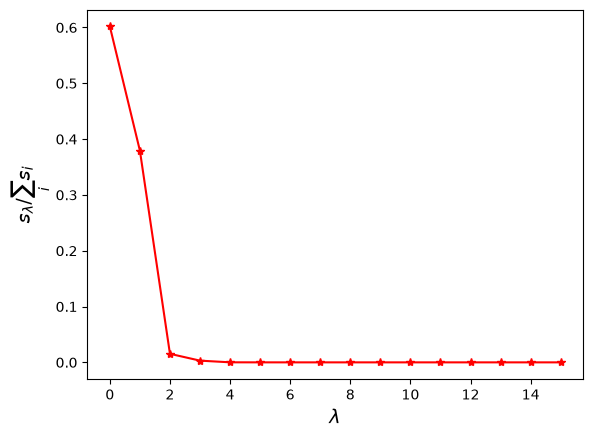

In [5]:
######################       TIME-DELAY EMBEDDING       ######################
# Hankel matrix of the measured u1 (delays of length 200), SVD, keep 4 time-delay coordinates
n_tdc = 4
tde = TimeDelayEmbedding(length=200, n_coordinates=n_tdc, shift=1).fit(X_train[:, :, 0])
T_h = tde.n_samples(T)  # time length of the new coordinates

plt.figure()
plt.plot(tde.singular_values / np.sum(tde.singular_values), "r*-")
plt.ylabel(r"$s_\lambda / \sum_{i}s_i$", fontsize=14)
plt.xlabel(r"$\lambda$", fontsize=14)
plt.show()

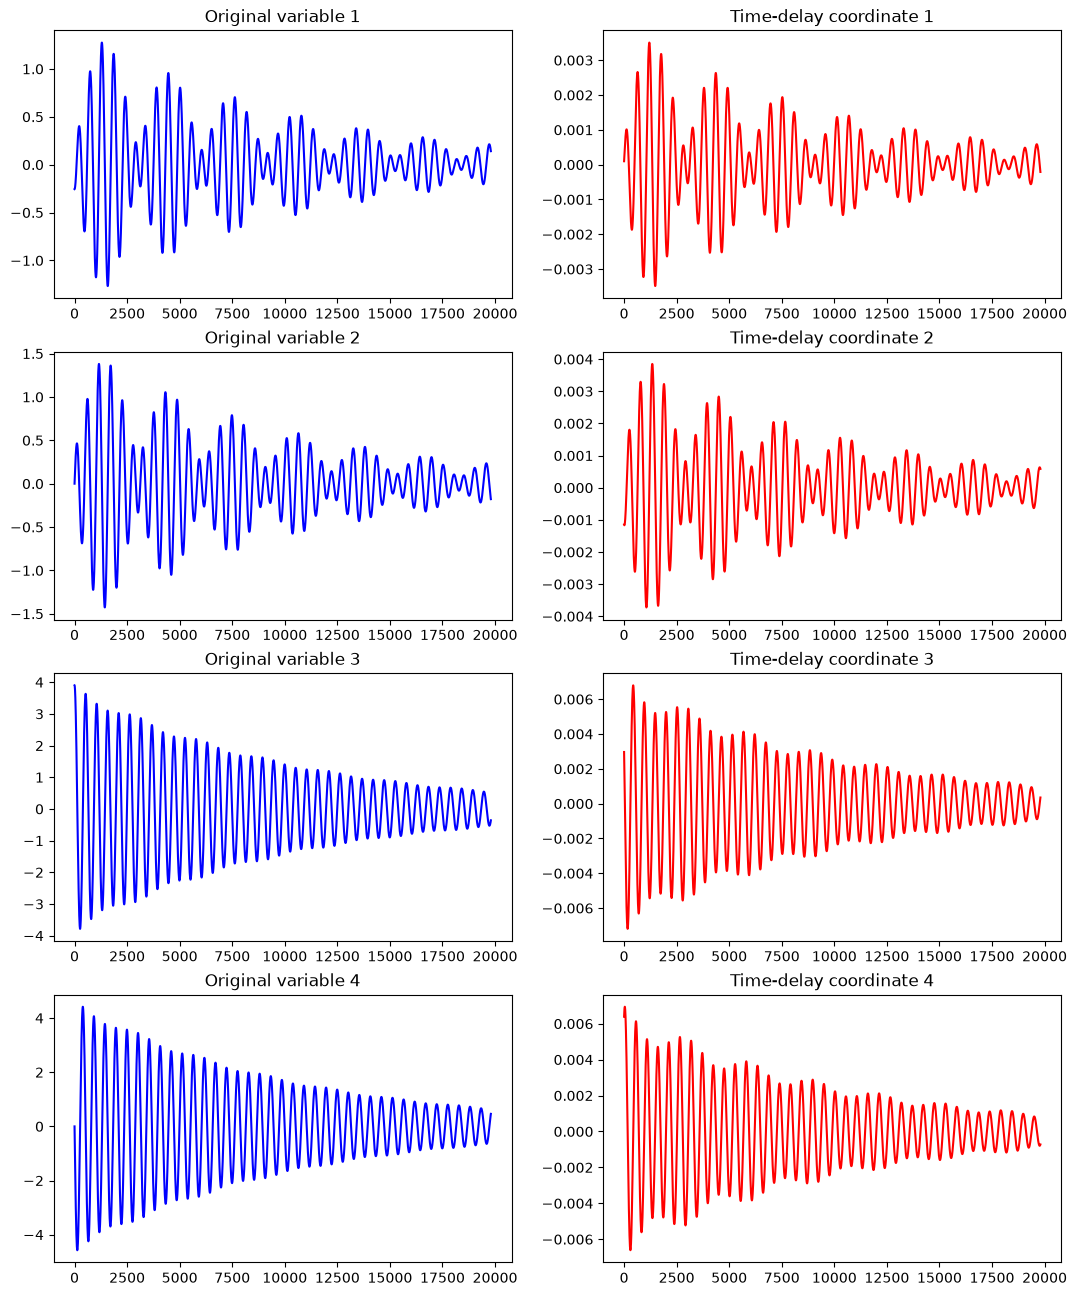

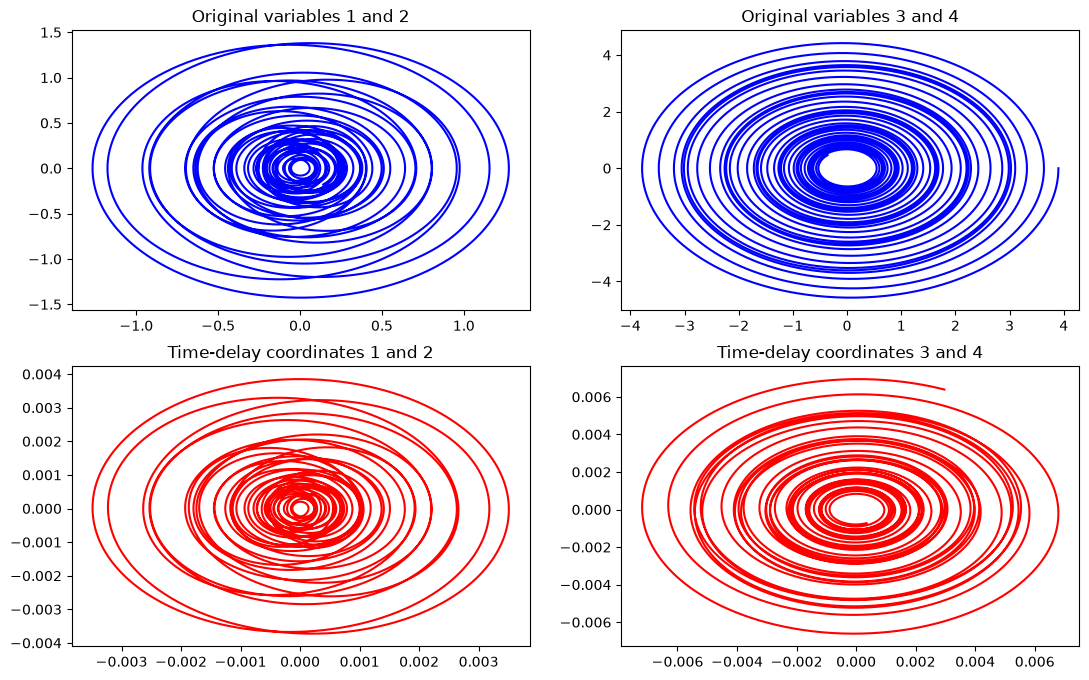

In [6]:
######################      TIME-DELAY COORDINATES       ######################
Z_train = [tde.transform(x[:, 0]) for x in X_train]
Z_test = [tde.transform(x[:, 0]) for x in X_test]

plt.figure(figsize=[13, 16])
for i in range(4):
    plt.subplot(421 + 2 * i)
    plt.plot(X_train[0, :T_h, i], "b")
    plt.title(f"Original variable {i + 1}", fontsize=12)
    plt.subplot(421 + 2 * i + 1)
    plt.plot(Z_train[0][:, i], "r")
    plt.title(f"Time-delay coordinate {i + 1}", fontsize=12)

plt.figure(figsize=[13, 8])
for i in range(2):
    plt.subplot(221 + i)
    plt.plot(X_train[0, :T_h, 2 * i], X_train[0, :T_h, 2 * i + 1], "b")
    plt.title(f"Original variables {2 * i + 1} and {2 * i + 2}", fontsize=12)
    plt.subplot(221 + i + 2)
    plt.plot(Z_train[0][:, 2 * i], Z_train[0][:, 2 * i + 1], "r")
    plt.title(f"Time-delay coordinates {2 * i + 1} and {2 * i + 2}", fontsize=12)
plt.show()

In [7]:
######################      PREPARE DATA for SINDy       ######################
dZ_train = [np.gradient(z, dt, axis=0) for z in Z_train]
P_train = [np.tile(p, (T_h, 1)) for p in param_train]
P_test = [np.tile(p, (T_h, 1)) for p in param_test]

# Library variables: time-delay coordinates, then the parameters
variables = [f"x{i + 1}" for i in range(n_tdc)] + param_names

In [8]:
######################      CREATE SINDy model       ######################
sindy = ps.SINDy(feature_library=ps.PolynomialLibrary(degree=3, include_bias=False),
                 optimizer=ps.STLSQ(threshold=5e-4))
sindy.fit(Z_train, t=dt, u=P_train, x_dot=dZ_train, feature_names=variables)

# Same cubic library, written symbolically (and differentiable with JAX)
library = SymbolicLibrary.polynomial(variables, degree=3, include_bias=False)
model = SparseModel.from_pysindy(sindy, library, n_params=len(param_names))
model.print()

(x1)' = -0.007*x1 - 1.027*x2 - 0.001*x3 - 0.009*x4
(x2)' = -0.001*k2*x1 + 0.004*k2*x3 + 1.004*x1 - 0.02*x2 - 0.15*x3
(x3)' = -0.001*k2*x1 - 0.006*k2*x2 + 0.019*k2*x4 + 0.005*x1 + 0.157*x2 - 0.002*x3 - 1.246*x4
(x4)' = -0.001*k2**2*x2 + 0.002*k2**2*x3 - 0.189*k2*x1 + 0.044*k2*x2 + 0.834*k2*x3 + 0.262*x1 - 0.049*x2 - 0.061*x3 - 0.011*x4


Real parameters: [1.2]


/Users/contip/Desktop/ekfsindy/EKF-SINDy/.venv/lib/python3.13/site-packages/pysindy/_core.py:621: UserWarning: Last time point dropped in simulation because interpolation of control input was used. To avoid this, pass in a callable for u.
  warnings.warn(


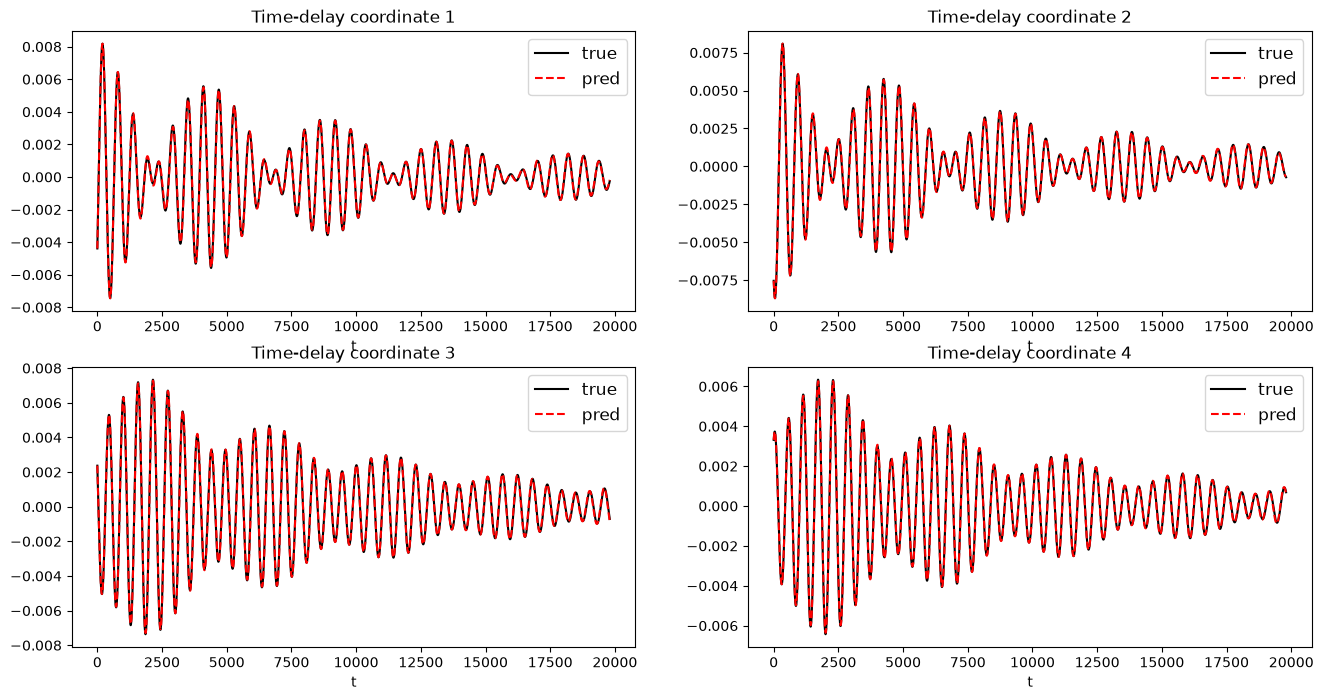

In [9]:
######################      PREDICT       ######################
idx_test = 0
true_param = param_test[idx_test]
print("Real parameters:", true_param)

#Predict the evolution of the time-delay coordinates:
pred = sindy.simulate(Z_test[idx_test][0, :], t=t[:T_h], u=P_test[idx_test])

plt.figure(figsize=[16, 8])
for i in range(4):
    plt.subplot(221 + i)
    plt.plot(Z_test[idx_test][:, i], "k", label="true")
    plt.plot(pred[:, i], "r--", label="pred")
    plt.title(f"Time-delay coordinate {i + 1}", fontsize=12)
    plt.xlabel("t")
    plt.legend(fontsize=12)
plt.show()

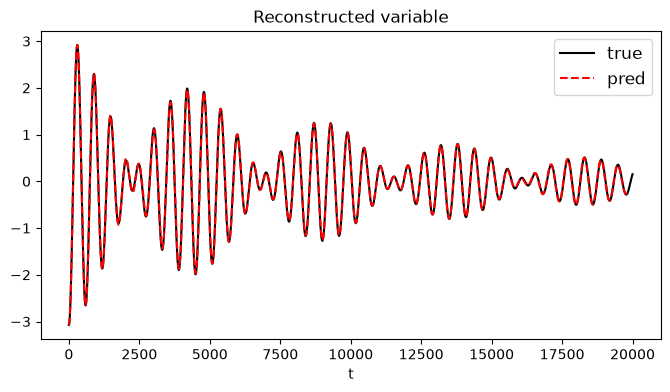

MSE 0.0008497322856452222


In [10]:
######################      RECONSTRUCTION       ######################
#Reconstruct the observed variable from the time-delay coordinates:
x_rec = tde.inverse_transform(pred)

plt.figure(figsize=[8, 4])
plt.plot(X_test[idx_test, :, 0], "k", label="true")
plt.plot(x_rec[:, 0], "r--", label="pred")
plt.title("Reconstructed variable", fontsize=12)
plt.xlabel("t")
plt.legend(fontsize=12)
plt.show()

print("MSE", mean_squared_error(X_test[idx_test, :T_h - 1, 0], x_rec[:T_h - 1, 0]))

## Kalman Filter

In [11]:
# Kalman filter part - measurements of u1 only, with noise (SNR = 15 dB)
N_x = n_tdc  # states: the time-delay coordinates
snr_noise_displ = 15

out_no_noise_axis = X_test[idx_test, :T_h, 0]
out_axis = add_noise_with_snr(X_test[idx_test, :, 0], snr_noise_displ)[:T_h]
t_axis = t[:T_h]

In [12]:
# Kalman filter initialisation
param_rel_error = 0.2
p_init = true_param * (1 + param_rel_error)

# Initial uncertainty, process noise (states, then k2) and measurement noise
P0 = np.diag([1e-6] * N_x + [1e-2])
Q = np.diag([1e-10, 1e-10, 1e-8, 1e-8, 2e-6])
R = [[5e-4]]

# u1 is the first delayed sample, a linear function of the time-delay coordinates
ekf = AugmentedEKF(model, observation.linear(tde.observation_matrix), Q=Q, R=R, dt=dt)
z0 = model.augmented_state(Z_test[idx_test][0], p_init)  # [x1..x4, parameters]

In [13]:
# Kalman filter run
result = ekf.run(z0, P0, out_axis)

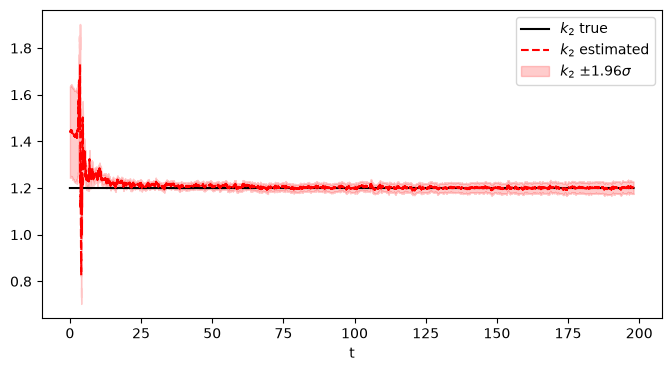

In [14]:
#%% stiffness k2
plt.figure(figsize=[8, 4])
plot_estimate(t_axis, result, N_x, truth=true_param[0], label=r"$k_2$")
plt.show()

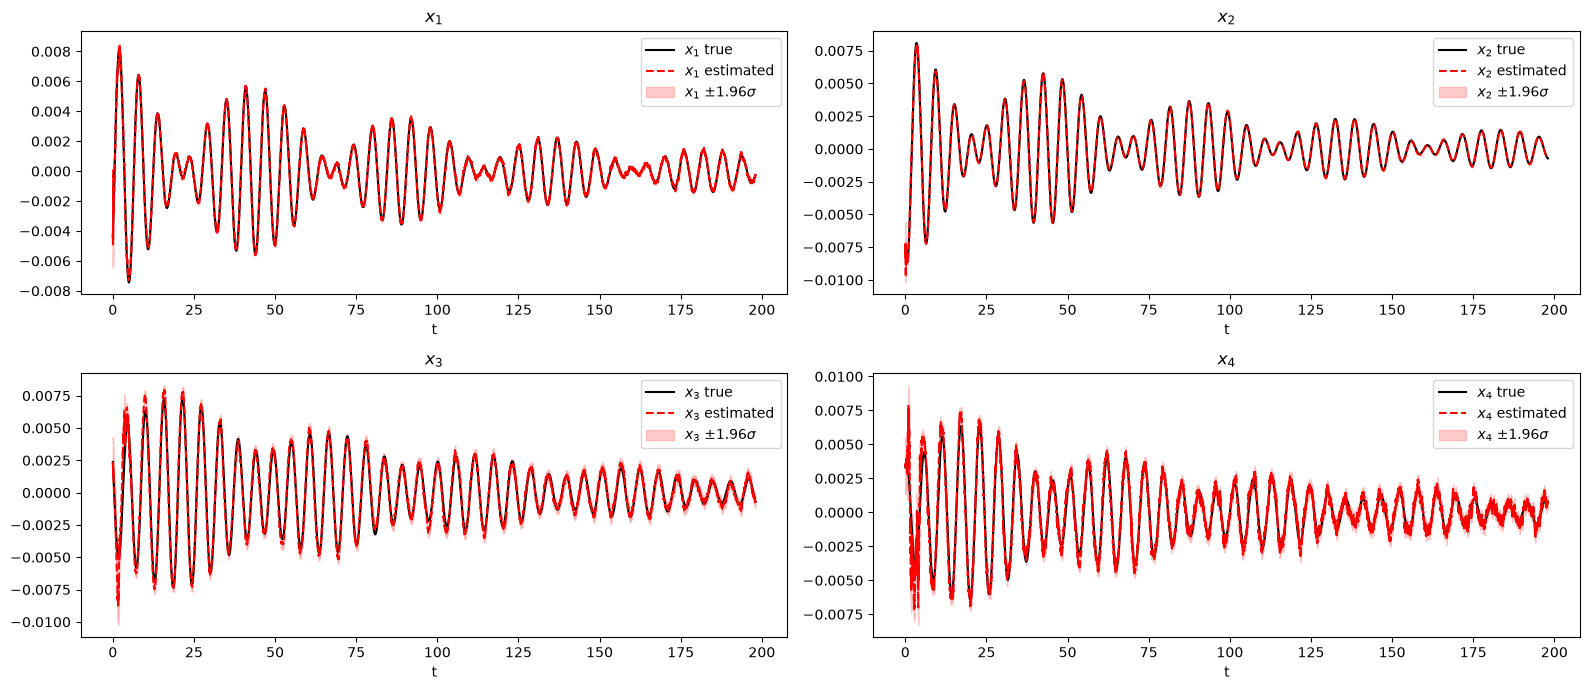

In [15]:
plot_estimates(t_axis, result, range(N_x), [f"$x_{i + 1}$" for i in range(N_x)],
               truths=[Z_test[idx_test][:, i] for i in range(N_x)])
plt.show()

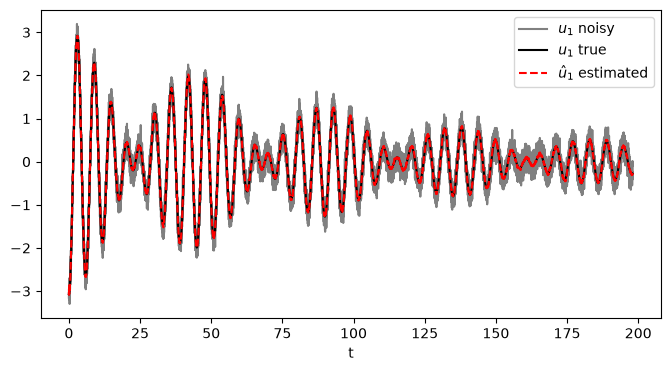

In [16]:
#%% observed variable
plt.figure(figsize=[8, 4])
plt.plot(t_axis, out_axis, color="gray", label="$u_1$ noisy")
plt.plot(t_axis, out_no_noise_axis, "k", label="$u_1$ true")
plt.plot(t_axis, result.obs[:, 0], "r--", label=r"$\hat{u}_1$ estimated")
plt.legend()
plt.xlabel("t")
plt.show()